# classify_text baseline: TF-IDF + calibrated LinearSVC

Reads `data/corpus.json` (built by `build_corpus.py`). Fits on **train**, evaluates on **val**.
The **test** split is only touched in the last cell, once, after tuning is finished.

In [ ]:
import os, json, random, time
from collections import Counter, defaultdict
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             log_loss, ConfusionMatrixDisplay)
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.svm import LinearSVC

SEED = 42
CORPUS = os.environ.get("CORPUS", "../data/corpus.json")
MODEL_OUT = os.environ.get("MODEL_OUT", "server/models/tfidf_svc.joblib")
PER_CLASS = None  

## 1. Load data

In [5]:
d = json.loads(Path(CORPUS).read_text(encoding="utf-8"))
LABELS = sorted(d["meta"]["labels"])
split = defaultdict(lambda: {"id": [], "X": [], "y": []})
for r in d["articles"]:
    s = split[r["split"]]
    s["id"].append(r["id"]); s["X"].append(r["text_norm"]); s["y"].append(r["label"])

for name in ("train", "val", "test"):
    print(f"{name:5s} {len(split[name]['y']):6d}", dict(sorted(Counter(split[name]['y']).items())))

train  39676 {'culture': 5665, 'finance': 5457, 'medical': 5715, 'politics': 5715, 'religion': 5706, 'sports': 5706, 'tech': 5712}
val     4404 {'culture': 629, 'finance': 606, 'medical': 635, 'politics': 634, 'religion': 633, 'sports': 633, 'tech': 634}
test    1000 {'culture': 143, 'finance': 143, 'medical': 143, 'politics': 143, 'religion': 143, 'sports': 143, 'tech': 142}


words per article: median 262 | p90 782 | p99 1630 | max 5786


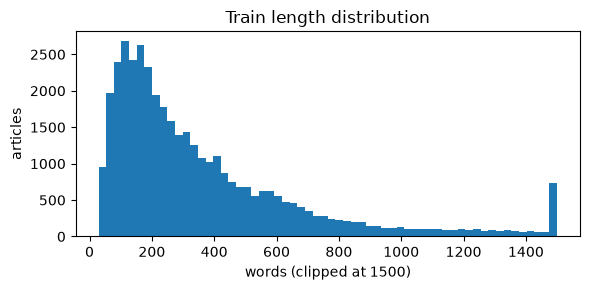

In [6]:
# article length (words): BERT truncates at 512 tokens, TF-IDF does not
lengths = np.array([len(x.split()) for x in split["train"]["X"]])
print("words per article: median %d | p90 %d | p99 %d | max %d" % (
    np.median(lengths), np.percentile(lengths, 90), np.percentile(lengths, 99), lengths.max()))
plt.figure(figsize=(6, 3)); plt.hist(np.clip(lengths, 0, 1500), bins=60)
plt.xlabel("words (clipped at 1500)"); plt.ylabel("articles"); plt.title("Train length distribution")
plt.tight_layout(); plt.show()

## 2. Model

Word 1-2-grams + character 2-5-grams (`char_wb`, helps with Arabic morphology and spelling variants).
`LinearSVC` has no `predict_proba`, so it is wrapped in `CalibratedClassifierCV` (5-fold sigmoid).
The vectorizers are fitted on the training data only.

In [7]:
def build_model(C_svc=0.5):
    feats = FeatureUnion([
        ("word", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_df=0.8,
                                 sublinear_tf=True, max_features=300_000)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3,
                                 sublinear_tf=True, max_features=400_000)),
    ])
    clf = CalibratedClassifierCV(LinearSVC(C=C_svc), method="sigmoid", cv=5)
    return Pipeline([("tfidf", feats), ("clf", clf)])

def subsample(X, y, per_class):
    rng = random.Random(SEED); idx = defaultdict(list)
    for i, l in enumerate(y): idx[l].append(i)
    keep = [i for ids in idx.values() for i in (rng.shuffle(ids) or ids)[:per_class]]
    return [X[i] for i in keep], [y[i] for i in keep]

Xtr, ytr = split["train"]["X"], split["train"]["y"]
if PER_CLASS:
    Xtr, ytr = subsample(Xtr, ytr, PER_CLASS)

model = build_model()
t = time.time(); model.fit(Xtr, ytr)
print(f"fit on {len(ytr)} articles in {time.time()-t:.0f}s")

fit on 39676 articles in 204s


## 3. Evaluate on val

In [8]:
def ece(proba, y_true, classes, bins=10):
    conf = proba.max(1)
    correct = (np.array(classes)[proba.argmax(1)] == np.array(y_true)).astype(float)
    edges = np.linspace(0, 1, bins + 1); err = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): err += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return err

def evaluate(model, X, y, title):
    proba = model.predict_proba(X); classes = list(model.classes_)
    pred = np.array(classes)[proba.argmax(1)]
    print(f"{title}: macro-F1 {f1_score(y, pred, average='macro'):.4f} | "
          f"acc {np.mean(pred == np.array(y)):.4f} | "
          f"log-loss {log_loss(y, proba, labels=classes):.4f} | ECE {ece(proba, y, classes):.4f}")
    print(classification_report(y, pred, labels=LABELS, digits=3))
    return proba, pred

Xva, yva = split["val"]["X"], split["val"]["y"]
proba_va, pred_va = evaluate(model, Xva, yva, "VAL")

VAL: macro-F1 0.9836 | acc 0.9837 | log-loss 0.0622 | ECE 0.0102
              precision    recall  f1-score   support

     culture      0.984     0.962     0.973       629
     finance      0.988     0.987     0.988       606
     medical      0.989     0.989     0.989       635
    politics      0.986     0.986     0.986       634
    religion      0.967     0.978     0.973       633
      sports      0.992     0.998     0.995       633
        tech      0.980     0.986     0.983       634

    accuracy                          0.984      4404
   macro avg      0.984     0.984     0.984      4404
weighted avg      0.984     0.984     0.984      4404



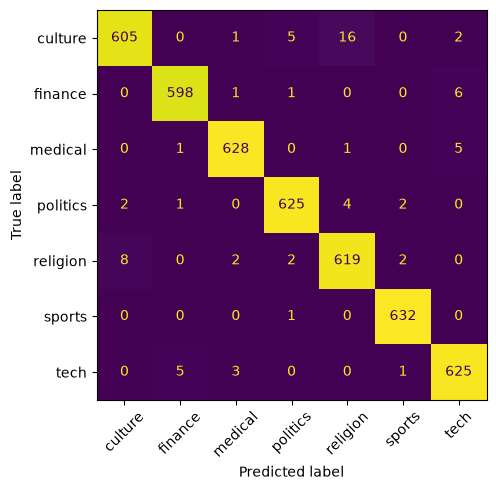

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(yva, pred_va, labels=LABELS), display_labels=LABELS
                       ).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout(); plt.show()

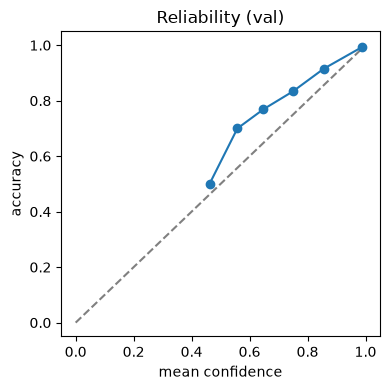

In [10]:
# reliability diagram: are the confidence values trustworthy? (the agent relies on them)
conf = proba_va.max(1); correct = (pred_va == np.array(yva)).astype(float)
edges = np.linspace(0, 1, 11); xs, ys = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (conf > lo) & (conf <= hi)
    if m.sum() >= 5: xs.append(conf[m].mean()); ys.append(correct[m].mean())
plt.figure(figsize=(4, 4)); plt.plot([0, 1], [0, 1], "--", c="gray"); plt.plot(xs, ys, "o-")
plt.xlabel("mean confidence"); plt.ylabel("accuracy"); plt.title("Reliability (val)")
plt.tight_layout(); plt.show()

## 4. Error analysis

In [11]:
wrong = np.where(pred_va != np.array(yva))[0]
print(len(wrong), "val errors;", "most frequent confusions (true -> pred):")
for (t, p), n in Counter((yva[i], pred_va[i]) for i in wrong).most_common(8):
    print(f"  {t:9s} -> {p:9s} {n}")
print()
for i in wrong[:5]:
    top3 = sorted(zip(model.classes_, proba_va[i]), key=lambda x: -x[1])[:3]
    print(split["val"]["id"][i], "| true:", yva[i], "| top-3:", [(c, round(p, 2)) for c, p in top3])
    print("   ", Xva[i][:200], "\n")

72 val errors; most frequent confusions (true -> pred):
  culture   -> religion  16
  religion  -> culture   8
  finance   -> tech      6
  culture   -> politics  5
  medical   -> tech      5
  tech      -> finance   5
  politics  -> religion  4
  tech      -> medical   3

sanad_000006 | true: culture | top-3: [(np.str_('religion'), np.float64(0.45)), (np.str_('culture'), np.float64(0.41)), (np.str_('politics'), np.float64(0.06))]
    * الاطفال يغرقونفقط ليطعموا صغار السمكالاطفال يرقصونليطردوا الشيطان من رؤوسناالاطفال يطيرونالاطفال يركضونلنعرف ان الجحيم مجرد حديقه كبيرهالاطفال لا يموتونلا يموتون . . * راسي يؤلمني اظن ان اهلك وبخوك  

sanad_000091 | true: culture | top-3: [(np.str_('religion'), np.float64(0.98)), (np.str_('culture'), np.float64(0.01)), (np.str_('medical'), np.float64(0.01))]
    ابوظبي - الاء عبدالغني: استضافت مؤسسه بحر الثقافه امس محاضره للسياسي والدبلوماسي العراقي الدكتور عدنان الباجه جي، الذي رافق المغفور له باذن الله الشيخ زايد بن سلطان ال نهيان، طيب الله ثراه، وشغل

## 5. Save the model (for the `classify_text` MCP tool)

In [12]:
Path(MODEL_OUT).parent.mkdir(parents=True, exist_ok=True)
joblib.dump({"model": model, "labels": LABELS}, MODEL_OUT)
print("saved", MODEL_OUT)

saved server/models/tfidf_svc.joblib


## 6. Final test (run ONCE, only when tuning is finished)

Refits on train + val with the chosen hyperparameters, then scores the frozen test split.
Set `RUN_FINAL = True` to enable it.

In [13]:
RUN_FINAL = False
if RUN_FINAL:
    final = build_model()
    final.fit(split["train"]["X"] + split["val"]["X"], split["train"]["y"] + split["val"]["y"])
    Xte, yte = split["test"]["X"], split["test"]["y"]
    proba_te, pred_te = evaluate(final, Xte, yte, "TEST (final)")
    print(confusion_matrix(yte, pred_te, labels=LABELS))
    joblib.dump({"model": final, "labels": LABELS}, MODEL_OUT)
else:
    print("Test split untouched. Set RUN_FINAL = True when you are done tuning.")

Test split untouched. Set RUN_FINAL = True when you are done tuning.
